# 04: Geospatial analysis

Where do JFK trips actually go? 

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

spark = (
    SparkSession.builder
    .appName("mast30034_project1_geospatial")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.session.timeZone", "America/New_York")
    .getOrCreate()
)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/08/18 16:25:34 WARN Utils: Your hostname, DESKTOP-G75J20V, resolves to a loopback address: 127.0.1.1; using 172.25.167.45 instead (on interface eth0)
26/08/18 16:25:34 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/home/micha/mast30034-env/lib/python3.14/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/08/18 16:25:36 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [ ]:
zones_sf = gpd.read_file("../data/landing/misc/taxi_zones.shp")
zones_sf = zones_sf.to_crs("EPSG:4326")  # convert to lat/long for plotting

zone_lookup = pd.read_csv("../data/landing/misc/taxi+_zone_lookup.csv")

zones = zone_lookup.merge(zones_sf[["LocationID", "geometry"]], on="LocationID", how="inner")
zones = gpd.GeoDataFrame(zones, geometry="geometry", crs="EPSG:4326")

print(f"Zones with matched geometry: {len(zones)}")
zones.head()

Zones with matched geometry: 263


,LocationID,Borough,Zone,service_zone,geometry
0,1,EWR,Newark Airport,EWR,"POLYGON ((-74.18445 40.695, -74.18449 40.6951,..."
1,2,Queens,Jamaica Bay,Boro Zone,"MULTIPOLYGON (((-73.82338 40.63899, -73.82277 ..."
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone,"POLYGON ((-73.84793 40.87134, -73.84725 40.870..."
3,4,Manhattan,Alphabet City,Yellow Zone,"POLYGON ((-73.97177 40.72582, -73.97179 40.725..."
4,5,Staten Island,Arden Heights,Boro Zone,"POLYGON ((-74.17422 40.56257, -74.17349 40.562..."


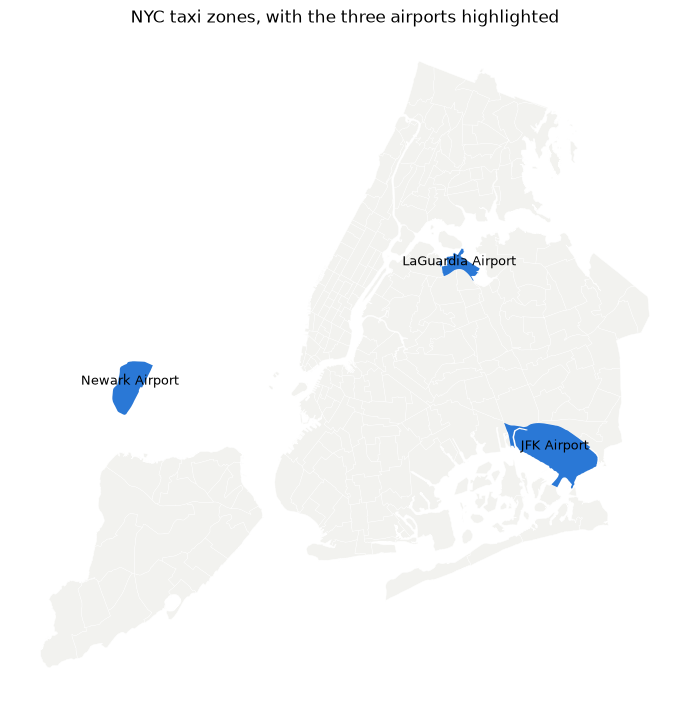

In [3]:
fig, ax = plt.subplots(figsize=(7, 8))
zones.plot(ax=ax, color="#f2f2ef", edgecolor="white", linewidth=0.3)

airports = zones[zones["LocationID"].isin([1, 132, 138])]
airports.plot(ax=ax, color="#2a78d6")
for _, row in airports.iterrows():
    centroid = row["geometry"].centroid
    ax.annotate(row["Zone"], (centroid.x, centroid.y), fontsize=9, ha="center")

ax.set_title("NYC taxi zones, with the three airports highlighted")
ax.set_axis_off()
plt.tight_layout()
plt.savefig("../plots/nyc_zones_airports.png", dpi=150)
plt.show()

## Where do JFK trips actually go?

For each pricing mechanism, what share of JFK pickups drop off in each zone?


In [4]:
def dest_distribution(sdf, location_col="DOLocationID"):
    """
    Compute each destination zone's share of trips in a Spark DataFrame, using
    the full distribution (no sampling).
    """
    total = sdf.count()
    counts = (
        sdf.groupBy(location_col)
        .count()
        .withColumn("share", F.col("count") / total)
        .toPandas()
    )
    return counts.rename(columns={location_col: "LocationID"})


yellow = spark.read.parquet("../data/curated/yellow_filtered/")
yellow_jfk = yellow.filter(F.col("PULocationID") == 132)

hvfhv = spark.read.parquet("../data/curated/hvfhv_filtered/")
hvfhv_jfk = hvfhv.filter(F.col("PULocationID") == 132)

flat_fare_dest = dest_distribution(yellow_jfk.filter(F.col("RatecodeID") == 2))
standard_dest = dest_distribution(yellow_jfk.filter(F.col("RatecodeID") == 1))
hvfhv_dest = dest_distribution(hvfhv_jfk)

print(f"Distinct destination zones - flat fare: {len(flat_fare_dest)}, "
      f"standard: {len(standard_dest)}, rideshare: {len(hvfhv_dest)}")


[Stage 2:==========================>                               (6 + 7) / 13]

                                                                                
/home/micha/mast30034-env/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/home/micha/mast30034-env/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/home/micha/mast30034-env/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()



[Stage 17:======================>                                (12 + 12) / 29]



Distinct destination zones - flat fare: 223, standard: 258, rideshare: 259


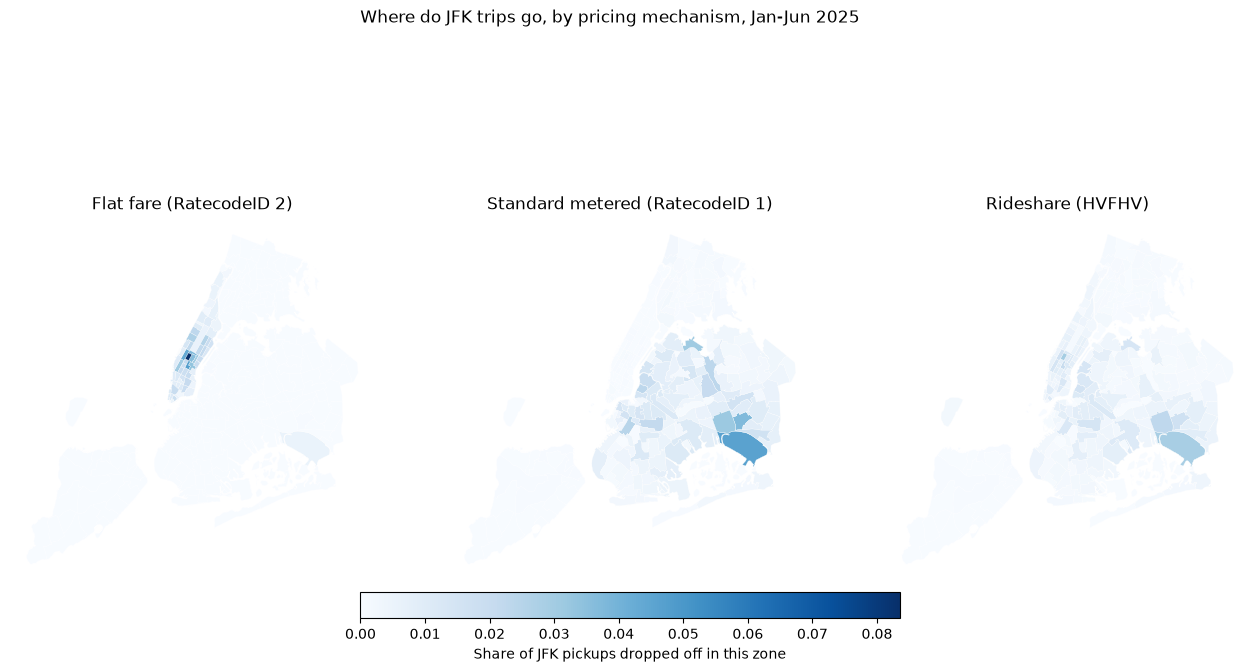

In [ ]:
def with_geometry(dest_df):
    """Attach zone geometry to a destination-distribution table for plotting."""
    merged = zones.merge(dest_df, on="LocationID", how="left")
    merged[["count", "share"]] = merged[["count", "share"]].fillna(0)
    return merged


flat_fare_map = with_geometry(flat_fare_dest)
standard_map = with_geometry(standard_dest)
hvfhv_map = with_geometry(hvfhv_dest)

vmax = max(flat_fare_map["share"].max(), standard_map["share"].max(), hvfhv_map["share"].max())

fig, axes = plt.subplots(1, 3, figsize=(16, 7))
titles = ["Flat fare (RatecodeID 2)", "Standard metered (RatecodeID 1)", "Rideshare (HVFHV)"]
for ax, gdf, title in zip(axes, [flat_fare_map, standard_map, hvfhv_map], titles):
    gdf.plot(column="share", ax=ax, cmap="Blues", vmin=0, vmax=vmax, edgecolor="white", linewidth=0.2)
    ax.set_title(title)
    ax.set_axis_off()

sm = plt.cm.ScalarMappable(cmap="Blues", norm=plt.Normalize(vmin=0, vmax=vmax))
fig.colorbar(sm, ax=axes, orientation="horizontal", fraction=0.05, pad=0.02, label="Share of JFK pickups dropped off in this zone")

fig.suptitle("Where do JFK trips go, by pricing mechanism, Jan-Jun 2025")
plt.savefig("../plots/jfk_destination_choropleth.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# Top 10 destination zones for flat-fare JFK trips specifically 
top_flat_fare_dest = (
    flat_fare_dest
    .merge(zone_lookup[["LocationID", "Zone", "Borough"]], on="LocationID", how="left")
    .sort_values("share", ascending=False)
    .head(10)
)
top_flat_fare_dest[["Zone", "Borough", "count", "share"]]

,Zone,Borough,count,share
22,Times Sq/Theatre District,Manhattan,38228,0.083485
44,Midtown South,Manhattan,21693,0.047375
47,Clinton East,Manhattan,19643,0.042898
48,Midtown North,Manhattan,17365,0.037923
79,Midtown Center,Manhattan,16560,0.036165
132,Murray Hill,Manhattan,15386,0.033601
135,East Chelsea,Manhattan,14075,0.030738
82,Midtown East,Manhattan,13930,0.030421
96,Upper West Side South,Manhattan,12283,0.026824
16,Upper East Side North,Manhattan,11550,0.025224


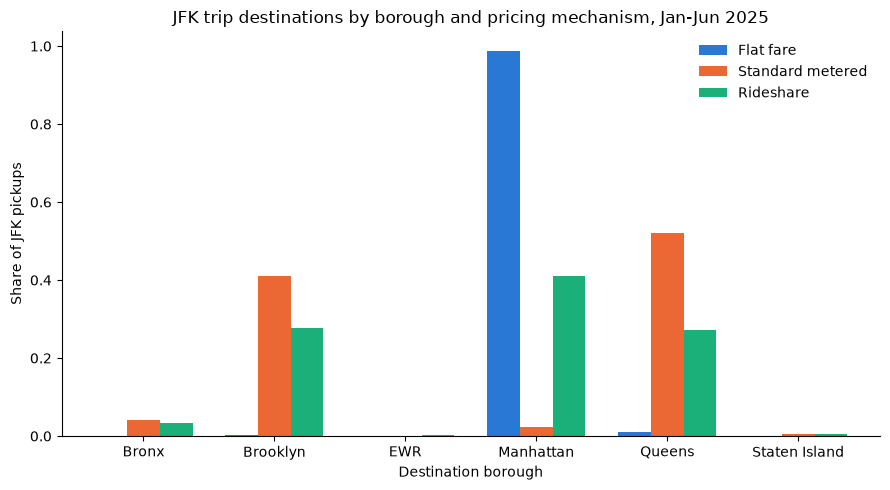

In [7]:
def borough_share(dest_df):
    """Roll a zone-level destination distribution up to borough level."""
    merged = dest_df.merge(zone_lookup[["LocationID", "Borough"]], on="LocationID", how="left")
    return merged.groupby("Borough")["share"].sum()


borough_comparison = pd.DataFrame({
    "Flat fare": borough_share(flat_fare_dest),
    "Standard metered": borough_share(standard_dest),
    "Rideshare": borough_share(hvfhv_dest),
}).fillna(0)

fig, ax = plt.subplots(figsize=(9, 5))
borough_comparison.plot(kind="bar", ax=ax, color=["#2a78d6", "#eb6834", "#1baf7a"], width=0.75)
ax.set_ylabel("Share of JFK pickups")
ax.set_xlabel("Destination borough")
ax.set_title("JFK trip destinations by borough and pricing mechanism, Jan-Jun 2025")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../plots/jfk_destination_borough.png", dpi=150)
plt.show()

In [8]:
flat_fare_dest.to_parquet("../data/curated/jfk_dest_flat_fare.parquet", index=False)
standard_dest.to_parquet("../data/curated/jfk_dest_standard.parquet", index=False)
hvfhv_dest.to_parquet("../data/curated/jfk_dest_hvfhv.parquet", index=False)
print("Saved curated destination-distribution tables.")

Saved curated destination-distribution tables.
